In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import CountVectorizer

# 1. Dataset Overview

This notebook explores the training set of the [Jigsaw Unintended Bias in Toxicity Classification](https://www.kaggle.com/c/jigsaw-unintended-bias-in-toxicity-classification) challenge: public comments from the *Civil Comments* platform, annotated by human raters with a toxicity score and the identities each comment mentions.

The analysis supports four design decisions for the rest of the project:

- the **evaluation metric**, given the class balance
- how to **split** the data into train, validation and test
- the **cleaning** steps and the **maximum sequence length** for DistilBERT
- which **identity subgroups** have enough data to evaluate model bias.

## 1.1 Loading and Column Structure



In [79]:
DATA_PATH = "../data/raw/jigsaw/train.csv"
df = pd.read_csv(DATA_PATH)

In [80]:
print(f"Shape of the dataset: {df.shape}")
print(f"Columns in the dataset: {df.columns.tolist()}")
print(f"Memory usage of the dataset: {df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

Shape of the dataset: (1804874, 45)
Columns in the dataset: ['id', 'target', 'comment_text', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female', 'heterosexual', 'hindu', 'homosexual_gay_or_lesbian', 'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim', 'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion', 'other_sexual_orientation', 'physical_disability', 'psychiatric_or_mental_illness', 'transgender', 'white', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'sexual_explicit', 'identity_annotator_count', 'toxicity_annotator_count']
Memory usage of the dataset: 1195.51 MB


In [81]:
df.head()

,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
1,59849,0.000000,Thank you!! This would make my life a lot less...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
2,59852,0.000000,This is such an urgent design problem; kudos t...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
3,59855,0.000000,Is this something I'll be able to install on m...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
4,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.0,0.021277,0.87234,0.0,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.0,4,47


## 1.2 Label Definition

The `target` column is the fraction of raters who considered the comment toxic, between 0 and 1. Following the official challenge rule, a comment is labeled **toxic** (1) when `target >= 0.5` and **non-toxic** (0) otherwise.


In [82]:
df["label"] = (df["target"] >= 0.5).astype(int)

In [83]:
examples = pd.concat([
    df[df["target"] == 0].head(1),
    df[df["target"].between(0.45, 0.55)].head(1),
    df[df["target"] >= 0.9].head(1),
])
examples[["comment_text", "target", "toxicity_annotator_count", "label"]]


,comment_text,target,toxicity_annotator_count,label
0,"This is so cool. It's like, 'would you want yo...",0.000000,4,0
6,hahahahahahahahhha suck it.,0.457627,59,0
31,Yet call out all Muslims for the acts of a few...,0.912500,80,1


# 2. Label Distribution

This section studies the toxicity label: 
- how balanced the two classes are and how the original score is distribute
- how many comments fall in the ambiguous zone where raters disagree

 The results determine the evaluation metric and whether the split must be stratified.


## 2.1 Class Balance



       comments  share (%)
label                     
0       1660540       92.0
1        144334        8.0


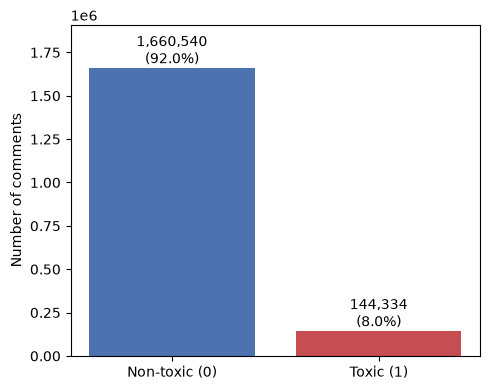

In [84]:
counts = df["label"].value_counts().sort_index()
shares = counts / len(df) * 100

print(pd.DataFrame({"comments": counts, "share (%)": shares.round(2)},
                   index=pd.Index([0, 1], name="label")))

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Non-toxic (0)", "Toxic (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.bar_label(bars, labels=[f"{c:,}\n({s:.1f}%)" for c, s in zip(counts, shares)])
ax.set_ylabel("Number of comments")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()


## 2.2 Toxicity Score Distribution

We plot the distribution of the original `target` score, on a logarithmic scale, and measure the ambiguous zone between 0.4 and 0.6, where raters disagree.


In [85]:
ambiguous = (df["target"] >= 0.4) & (df["target"] < 0.6)
toxic = df["label"] == 1

print(f"Comments with target = 0: {(df['target'] == 0).mean() * 100:.1f}%")
print(f"Ambiguous zone [0.4, 0.6): {ambiguous.sum():,} comments ({ambiguous.mean() * 100:.1f}% of all)")
print(f"Toxic comments with target in [0.5, 0.6): {(toxic & ambiguous).sum():,} "
      f"({(toxic & ambiguous).sum() / toxic.sum() * 100:.1f}% of the toxic class)")
print(f"Comments with target exactly 0.5: {(df['target'] == 0.5).sum():,}")



Comments with target = 0: 70.1%
Ambiguous zone [0.4, 0.6): 105,066 comments (5.8% of all)
Toxic comments with target in [0.5, 0.6): 47,924 (33.2% of the toxic class)
Comments with target exactly 0.5: 37,896


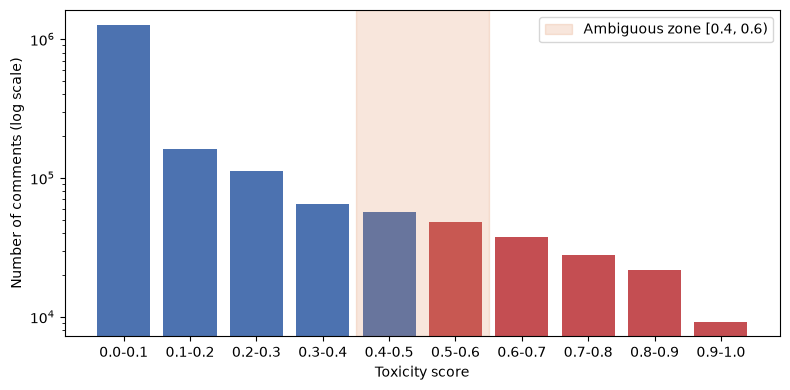

In [86]:

edges = np.round(np.arange(0, 1.1, 0.1), 1)
counts_by_bin, _ = np.histogram(df["target"], bins=edges)  # last bin includes 1.0

labels = [f"{a:.1f}-{b:.1f}" for a, b in zip(edges[:-1], edges[1:])]
colors = ["#4C72B0" if a < 0.5 else "#C44E52" for a in edges[:-1]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, counts_by_bin, color=colors)
ax.axvspan(3.5, 5.5, color="#DD8452", alpha=0.2, label="Ambiguous zone [0.4, 0.6)")
ax.set_yscale("log")
ax.set_xlabel("Toxicity score")
ax.set_ylabel("Number of comments (log scale)")
ax.legend()
plt.tight_layout()
plt.show()


## 2.3 Number of Raters per Comment

We look at how many raters scored each comment. With few raters, the score can only take a few values and a single vote can change the label.


In [87]:
n_raters = df["toxicity_annotator_count"]

print(f"Median raters per comment: {n_raters.median():.0f}")
print(f"Min: {n_raters.min()}, max: {n_raters.max():,}")
print(f"Comments with fewer than 10 raters: {(n_raters < 10).mean() * 100:.1f}%")


Median raters per comment: 4
Min: 3, max: 4,936
Comments with fewer than 10 raters: 81.2%


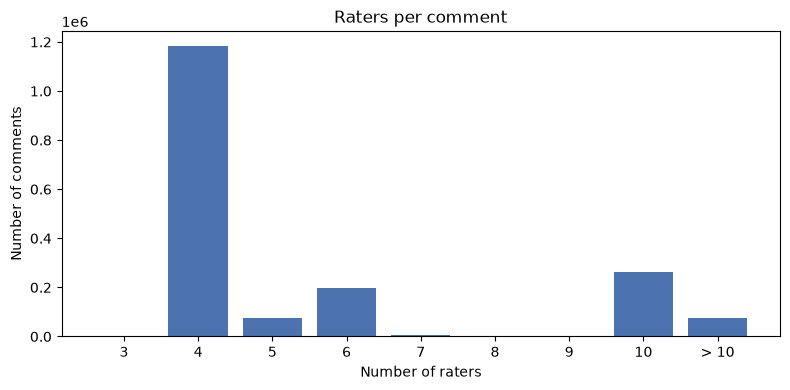

In [88]:
bucket = n_raters.clip(upper=11)
counts_raters = bucket.value_counts().sort_index()
labels = [str(k) if k <= 10 else "> 10" for k in counts_raters.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, counts_raters.values, color="#4C72B0")
ax.set_xlabel("Number of raters")
ax.set_ylabel("Number of comments")
ax.set_title("Raters per comment")
plt.tight_layout()
plt.show()


# 3. Data Quality Assessment

This section checks the comment text for problems that affect training and evaluation: 
- missing or empty values, 
- duplicated comments, unusual characters and patterns
-  comment length, and how comments are distributed across articles.


## 3.1 Missing and Empty Values

We count missing values in the columns used for modeling and look for comments whose text is empty or contains only whitespace. Identity columns are excluded here: their missing values mean the comment was not annotated, which is analyzed in Section 5.

In [89]:
key_columns = ["comment_text", "target", "article_id"]
print("Missing values:")
print(df[key_columns].isna().sum())

text = df["comment_text"].fillna("")
empty = text.str.strip() == ""
print(f"\nEmpty or whitespace-only comments (including NaN): {empty.sum():,}")
df.loc[empty & df["comment_text"].notna(), ["id", "comment_text", "target"]].head()


Missing values:
comment_text    3
target          0
article_id      0
dtype: int64

Empty or whitespace-only comments (including NaN): 3


,id,comment_text,target


In [90]:
df = df[df["comment_text"].notna()].reset_index(drop=True)
print(f"Rows after dropping missing text: {len(df):,}")


Rows after dropping missing text: 1,804,871


## 3.2 Duplicated Comments

We look for comments with the same text, both exactly and after normalization (lowercase and collapsed whitespace).
 We then check two problems duplicates can cause: 
 - identical texts with contradictory labels
 -  identical texts in different articles, which could leak from train into test.


In [91]:
normalized = df["comment_text"].str.lower().str.split().str.join(" ")

exact_dup = df["comment_text"].duplicated(keep=False)
norm_dup = normalized.duplicated(keep=False)

print(f"Comments whose exact text appears more than once: {exact_dup.sum():,} ({exact_dup.mean() * 100:.2f}%)")
print(f"Comments whose normalized text appears more than once: {norm_dup.sum():,} ({norm_dup.mean() * 100:.2f}%)")
print(f"Distinct normalized texts that are repeated: {normalized[norm_dup].nunique():,}")


Comments whose exact text appears more than once: 34,228 (1.90%)
Comments whose normalized text appears more than once: 40,881 (2.27%)
Distinct normalized texts that are repeated: 12,527


In [92]:
groups = df[norm_dup].assign(text_norm=normalized[norm_dup]).groupby("text_norm")

conflict = groups["label"].nunique() > 1
cross_article = groups["article_id"].nunique() > 1

print(f"Repeated texts with contradictory labels: {conflict.sum():,}")
print(f"Repeated texts that appear in more than one article: {cross_article.sum():,}")

# Most frequent repeated texts and their label agreement
summary = groups.agg(copies=("label", "size"), toxic_share=("label", "mean"),
                     articles=("article_id", "nunique"))
summary.sort_values("copies", ascending=False).head(10)


Repeated texts with contradictory labels: 808
Repeated texts that appear in more than one article: 7,578


,copies,toxic_share,articles
text_norm,,,
well said.,194,0.0,190
lol,176,0.0,168
no.,170,0.0,167
exactly.,136,0.0,133
yes.,132,0.0,130
why?,130,0.0,128
thank you.,126,0.0,125
exactly!,123,0.0,123
"sᴛᴀʀᴛ ᴡᴏʀᴋɪɴɢ ғʀᴏᴍ ʜᴏᴍᴇ! gʀᴇᴀᴛ ᴊᴏʙ ғᴏʀ sᴛᴜᴅᴇɴᴛs, sᴛᴀʏ-ᴀᴛ-ʜᴏᴍᴇ ᴍᴏᴍs ᴏʀ ᴀɴʏᴏɴᴇ ɴᴇᴇᴅɪɴɢ ᴀɴ ᴇxᴛʀᴀ ɪɴᴄᴏᴍᴇ... yᴏᴜ ᴏɴʟʏ ɴᴇᴇᴅ ᴀ ᴄᴏᴍᴘᴜᴛᴇʀ ᴀɴᴅ ᴀ ʀᴇʟɪᴀʙʟᴇ ɪɴᴛᴇʀɴᴇᴛ ᴄᴏɴɴᴇᴄᴛɪᴏɴ... mᴀᴋᴇ $90 ʜᴏᴜʀʟʏ ᴀɴᴅ ᴜᴘ ᴛᴏ $12000 ᴀ ᴍᴏɴᴛʜ ʙʏ ғᴏʟʟᴏᴡɪɴɢ ʟɪɴᴋ ᴀᴛ ᴛʜᴇ ʙᴏᴛᴛᴏᴍ ᴀɴᴅ sɪɢɴɪɴɢ ᴜᴘ... yᴏᴜ ᴄᴀɴ ʜᴀᴠᴇ ʏᴏᴜʀ ғɪʀsᴛ ᴄʜᴇᴄᴋ ʙʏ ᴛʜᴇ ᴇɴᴅ ᴏғ ᴛʜɪs ᴡᴇᴇᴋ... +++++++++http://www.cashapp24.com/",117,0.0,102


In [93]:
conflict_texts = conflict[conflict].index
summary.loc[conflict_texts].sort_values("copies", ascending=False).head(10)


,copies,toxic_share,articles
text_norm,,,
nonsense.,63,0.031746,61
how soon the failed harpercons forget that harper was the worst pm we ever had. record deficits. record debt. the worst fiscal record in 80 years. all harper accomplished was adding $160 billion to the national debt plus a lot of corruption and electoral fraud. oliver actually made a joke about having children to pay for harper's debt.,48,0.041667,1
troll,44,0.590909,32
"the domestic terrorists at the company called ""civil comments"" are attempting to destroy your first amendment right to free speech! only in communist countries or in nazi germany you had to have approval of your speech by your peers! that's not the united states of america! that's russia under the iron fist of a loser named putin! resist losing your 1st amendment right! here is the communists website i hope all hackers that are reading this understand it is time to take this website down are you listening @ ""anonymous"" our free-speech is being destroyed by these losers be a real american patriot like thomas jefferson and george washington that fought for our first amendment rights for free speech ! https://www.getcivil.com",40,0.400000,9
lock him up!,37,0.162162,36
"h.l. mencken’s prediction: “as democracy is perfected, the office of the president represents, more and more closely, the inner soul of the people. on some great and glorious day, the plain folks of the land will reach their heart’s desire at last, and the white house will be occupied by a downright fool and complete narcissist moron.” -h.l. mencken the baltimore evening sun, july 26, 1920",34,0.882353,33
lock her up!,23,0.173913,17
that's just silly.,22,0.727273,18
"shakespeare’s hamlet, who suffered from melancholia, expressed the sentiment – “how weary, stale, flat and unprofitable seem to me the workings of this world. it is an unweeded garden and things rank and gross in nature possess it merely”",21,0.047619,20


## 3.3 Unusual Characters and Patterns

We count comments containing patterns that may affect tokenization.


In [94]:
text = df["comment_text"]

patterns = {
    "line break": text.str.contains(r"\n", regex=True),
    "LS / PS separator": text.str.contains("[\u2028\u2029]", regex=True),
    "URL": text.str.contains(r"https?://|www\.", regex=True),
    "ellipsis": text.str.contains(r"\.\.\.|…", regex=True),
    "no letters": ~text.str.contains(r"[A-Za-z]", regex=True),
    "look-alike letters": text.str.contains("[\u1d00-\u1d7f\u0280-\u02af]", regex=True),
}

pattern_table = pd.DataFrame({
    "comments": {name: mask.sum() for name, mask in patterns.items()},
    "share (%)": {name: mask.mean() * 100 for name, mask in patterns.items()},
    "toxic (%)": {name: df.loc[mask, "label"].mean() * 100 for name, mask in patterns.items()},
}).round(2)
pattern_table


,comments,share (%),toxic (%)
line break,565427,31.33,7.48
LS / PS separator,54,0.00,5.56
URL,53297,2.95,3.74
ellipsis,242227,13.42,8.28
no letters,368,0.02,0.00
look-alike letters,483,0.03,0.83


In [95]:
for name, mask in patterns.items():
    print(f"--- {name} ---")
    for sample in text[mask].sample(min(3, mask.sum()), random_state=42):
        print(repr(sample[:150]))
    print()


--- line break ---
'IRT Larry Meacham: "The federal government will demand we return $750 million."\nSo, your faulty democrat logic is that we should pay billions more, so'
'Education Minister Don Morgan should visit the new public library in Halifax. He may quickly realize, like everyone who goes there, what an astounding'
"When you start piecing together the Trump story, basically everywhere you look, whether it's residents in his Trump-branded buildings, or his business"

--- LS / PS separator ---
"-they're\nT͟Her/\ncontraction\n1. they are.\u2028\n\nversus\n\n-their\nT͟Her/\ndeterminer\n1. \u2028belonging to or associated with the people or things previously mentio"
"Ronald Reagan signed a bill legalizing abortion.\u2028\u2028\n\nWatch as the right wingers move to withdraw Ronnie's sainthood."
"President Kennedy and Martin Luther King were both killed because they called for an end to the War on Vietnam ...\n\n---\n\nPresident Kennedy's June 10, "

--- URL ---
"Who needs a wall?  I

## 3.4 Comment Length

We measure comment length in words for the full dataset, comparing toxic and non-toxic comments. We then measure length in DistilBERT tokens on a random sample of 100,000 comments, since the model truncates every comment to a fixed number of tokens.

In [96]:
df["n_words"] = df["comment_text"].str.split().str.len()

word_stats = df.groupby("label")["n_words"].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(1)
word_stats.index = ["Non-toxic (0)", "Toxic (1)"]
word_stats


,count,mean,std,min,5%,50%,95%,99%,max
Non-toxic (0),1660537.0,51.5,46.5,1.0,5.0,35.0,159.0,178.0,317.0
Toxic (1),144334.0,48.4,42.6,1.0,6.0,34.0,150.0,177.0,311.0


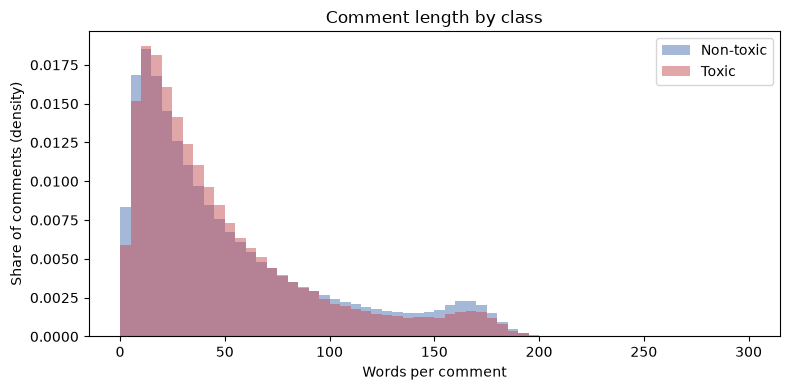

In [97]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, name, color in [(0, "Non-toxic", "#4C72B0"), (1, "Toxic", "#C44E52")]:
    ax.hist(df.loc[df["label"] == label, "n_words"], bins=60, range=(0, 300),
            density=True, alpha=0.5, label=name, color=color)
ax.set_xlabel("Words per comment")
ax.set_ylabel("Share of comments (density)")
ax.set_title("Comment length by class")
ax.legend()
plt.tight_layout()
plt.show()


In [98]:


tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

sample = df["comment_text"].sample(100_000, random_state=42).tolist()
n_tokens = pd.Series([len(ids) for ids in tokenizer(sample)["input_ids"]])

print(n_tokens.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
for limit in [128, 256, 512]:
    print(f"Comments longer than {limit} tokens: {(n_tokens > limit).mean() * 100:.1f}%")


count    100000.0
mean         68.6
std          58.8
min           3.0
50%          48.0
90%         166.0
95%         204.0
99%         232.0
max         463.0
dtype: float64
Comments longer than 128 tokens: 15.9%
Comments longer than 256 tokens: 0.1%
Comments longer than 512 tokens: 0.0%


## 3.5 Comments per Article

Comments under the same article share topic and vocabulary, so the split will assign whole articles to a single set. We check that there are enough articles and that no single article holds a large share of the data.


In [99]:
per_article = df["article_id"].value_counts()

print(f"Distinct articles: {len(per_article):,}")
print(per_article.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print(f"\nLargest article: {per_article.iloc[0]:,} comments "
      f"({per_article.iloc[0] / len(df) * 100:.2f}% of the data)")
print(f"Top 10 articles: {per_article.head(10).sum() / len(df) * 100:.2f}% of the data")


Distinct articles: 105,380
count    105380.0
mean         17.1
std          39.4
min           1.0
50%           4.0
90%          43.0
99%         192.0
max        1377.0
Name: count, dtype: float64

Largest article: 1,377 comments (0.08% of the data)
Top 10 articles: 0.52% of the data


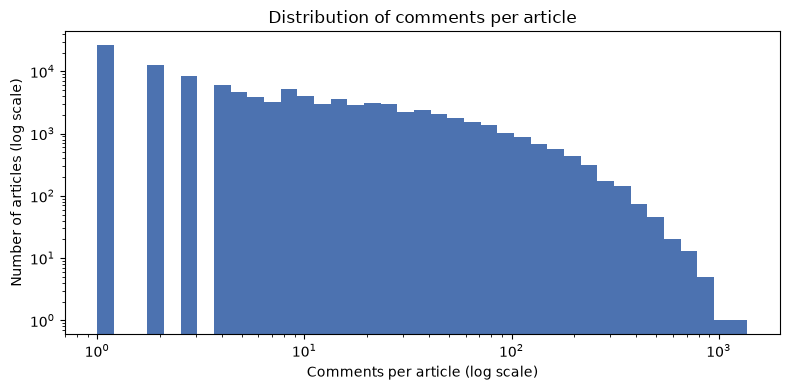

In [100]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(per_article.max()), 40)
ax.hist(per_article, bins=bins, color="#4C72B0")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Comments per article (log scale)")
ax.set_ylabel("Number of articles (log scale)")
ax.set_title("Distribution of comments per article")
plt.tight_layout()
plt.show()


# 4. Linguistic Signals of Toxicity

This section looks at surface features of the text that separate toxic from non-toxic comments: the words most associated with toxicity, and stylistic signals such as capital letters and exclamation marks. These are the signals a bag-of-words baseline can exploit; DistilBERT should go beyond them by using context.

## 4.1 Words Most Associated with Toxicity

For each word we compute the share of toxic comments and the share of non-toxic comments that contain it,and rank words by the ratio between the two. 


In [ ]:
vectorizer = CountVectorizer(binary=True, min_df=500, stop_words="english")
X = vectorizer.fit_transform(df["comment_text"])
vocab = vectorizer.get_feature_names_out()

is_toxic = df["label"].values == 1
toxic_rate = np.asarray(X[is_toxic].mean(axis=0)).ravel()
nontoxic_rate = np.asarray(X[~is_toxic].mean(axis=0)).ravel()

word_ratio = pd.DataFrame({
    "toxic (%)": toxic_rate * 100,
    "non-toxic (%)": nontoxic_rate * 100,
    "ratio": toxic_rate / nontoxic_rate,
}, index=vocab).sort_values("ratio", ascending=False)

print(f"Words considered: {len(vocab):,}")
word_ratio.head(20).round(2)


Words considered: 9,236


,toxic (%),non-toxic (%),ratio
idiot,3.48,0.03,103.42
idiots,2.38,0.03,89.97
moron,1.12,0.02,64.53
morons,0.65,0.01,60.27
stupidity,2.14,0.04,56.88
shit,0.55,0.01,55.76
stupid,8.96,0.20,45.56
idiotic,0.94,0.02,42.80
hypocrite,0.98,0.03,33.94
scum,0.68,0.02,33.69


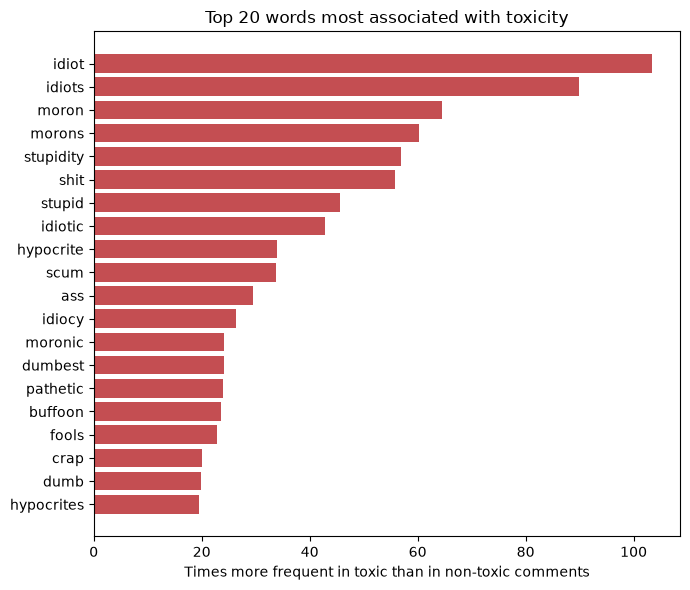

In [102]:
top = word_ratio.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["ratio"], color="#C44E52")
ax.set_xlabel("Times more frequent in toxic than in non-toxic comments")
ax.set_title("Top 20 words most associated with toxicity")
plt.tight_layout()
plt.show()


## 4.2 Capital Letters and Exclamation Marks

We check whether writing style separates the classes. Note that the uncased DistilBERT model lowercases its input, so it cannot see capitalization.


In [103]:
text = df["comment_text"]
letters = text.str.count(r"[A-Za-z]")
capitals = text.str.count(r"[A-Z]")

style = {
    "word in capitals (3+ letters)": text.str.contains(r"\b[A-Z]{3,}\b", regex=True),
    "over 50% capital letters": (capitals / letters.replace(0, np.nan)) > 0.5,
    "exclamation mark": text.str.contains("!", regex=False),
}

style_table = pd.DataFrame({
    "comments": {name: mask.sum() for name, mask in style.items()},
    "share (%)": {name: mask.mean() * 100 for name, mask in style.items()},
    "toxic (%)": {name: df.loc[mask, "label"].mean() * 100 for name, mask in style.items()},
}).round(2)
style_table


,comments,share (%),toxic (%)
word in capitals (3+ letters),402106,22.28,8.06
over 50% capital letters,5722,0.32,11.76
exclamation mark,226157,12.53,10.70


# 5. Identity Subgroup Analysis

This section studies the identity attributes, which are used only to evaluate the model by subgroup and never as model input. We measure how many comments are annotated, which subgroups have enough data, how toxicity varies across subgroups, and how often subgroups overlap.


## 5.1 Annotation Coverage

We count the comments with identity annotations (any value, including 0) and, among them, those that belong to at least one subgroup (some identity >= 0.5).


In [104]:
IDENTITIES = [
    "male", "female", "transgender", "other_gender",
    "heterosexual", "homosexual_gay_or_lesbian", "bisexual", "other_sexual_orientation",
    "christian", "jewish", "muslim", "hindu", "buddhist", "atheist", "other_religion",
    "black", "white", "asian", "latino", "other_race_or_ethnicity",
    "physical_disability", "intellectual_or_learning_disability",
    "psychiatric_or_mental_illness", "other_disability",
]

# The 9 identities used in the official Jigsaw evaluation
MAIN_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
    "muslim", "black", "white", "psychiatric_or_mental_illness",
]

# Annotated: identity columns have a value, even if it is 0
annotated = df[IDENTITIES].notna().any(axis=1)

# Belongs: at least one identity reaches 0.5
belongs_any = (df[IDENTITIES] >= 0.5).any(axis=1)

print(f"Annotated comments (any value, including 0): {annotated.sum():,} ({annotated.mean() * 100:.1f}%)")
print(f"Not annotated (NaN): {(~annotated).sum():,} ({(~annotated).mean() * 100:.1f}%)")
print(f"\nAnnotated and belonging to at least one subgroup (>= 0.5): {belongs_any.sum():,} "
      f"({belongs_any.sum() / annotated.sum() * 100:.1f}% of annotated)")
print(f"Annotated but mentioning no identity: {(annotated & ~belongs_any).sum():,}")


Annotated comments (any value, including 0): 405,128 (22.4%)
Not annotated (NaN): 1,399,743 (77.6%)

Annotated and belonging to at least one subgroup (>= 0.5): 170,304 (42.0% of annotated)
Annotated but mentioning no identity: 234,824


## 5.2 Comments per Identity

We count, for each of the 24 identities, the comments that belong to it (value >= 0.5). 

The 9 identities used in the official Jigsaw evaluation are highlighted. *A comment can belong to several identities.*


In [105]:
members = (df[IDENTITIES] >= 0.5).sum().sort_values(ascending=False)

ranking = pd.DataFrame({
    "comments": members,
    "share of annotated (%)": (members / annotated.sum() * 100).round(2),
    "official": members.index.isin(MAIN_IDENTITIES),
})
ranking


,comments,share of annotated (%),official
female,53429,13.19,True
male,44484,10.98,True
christian,40423,9.98,True
white,25082,6.19,True
muslim,21006,5.19,True
black,14901,3.68,True
homosexual_gay_or_lesbian,10997,2.71,True
jewish,7651,1.89,True
psychiatric_or_mental_illness,4889,1.21,True
asian,4578,1.13,False


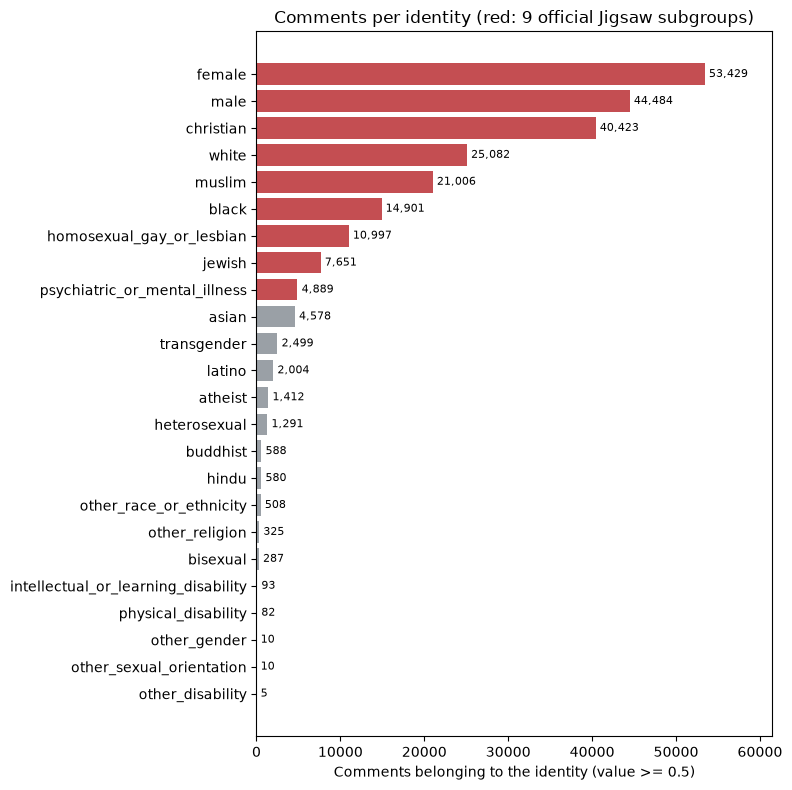

In [106]:
plot_data = members.iloc[::-1]
colors = ["#C44E52" if name in MAIN_IDENTITIES else "#9AA0A6" for name in plot_data.index]

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(plot_data.index, plot_data.values, color=colors)
ax.bar_label(bars, labels=[f"{v:,}" for v in plot_data.values], padding=3, fontsize=8)
ax.set_xlabel("Comments belonging to the identity (value >= 0.5)")
ax.set_title("Comments per identity (red: 9 official Jigsaw subgroups)")
ax.set_xlim(0, plot_data.max() * 1.15)
plt.tight_layout()
plt.show()

## 5.3 Toxic and Non-Toxic Comments per Subgroup

We take the 9 official Jigsaw subgroups and, for each one, keep the comments that belong to it (value >= 0.5). Among those comments we compute the share that is toxic and the share that is non-toxic.

In [107]:
rows = {}
for name in MAIN_IDENTITIES:
    labels = df.loc[df[name] >= 0.5, "label"]
    rows[name] = {
        "comments": len(labels),
        "toxic (%)": labels.mean() * 100,
        "non-toxic (%)": (1 - labels.mean()) * 100,
    }

toxicity_by_group = pd.DataFrame(rows).T.sort_values("toxic (%)", ascending=False)
toxicity_by_group["comments"] = toxicity_by_group["comments"].astype(int)
toxicity_by_group.round(1)

,comments,toxic (%),non-toxic (%)
black,14901,31.4,68.6
homosexual_gay_or_lesbian,10997,28.4,71.6
white,25082,28.1,71.9
muslim,21006,22.8,77.2
psychiatric_or_mental_illness,4889,21.1,78.9
jewish,7651,16.2,83.8
male,44484,15.0,85.0
female,53429,13.7,86.3
christian,40423,9.1,90.9


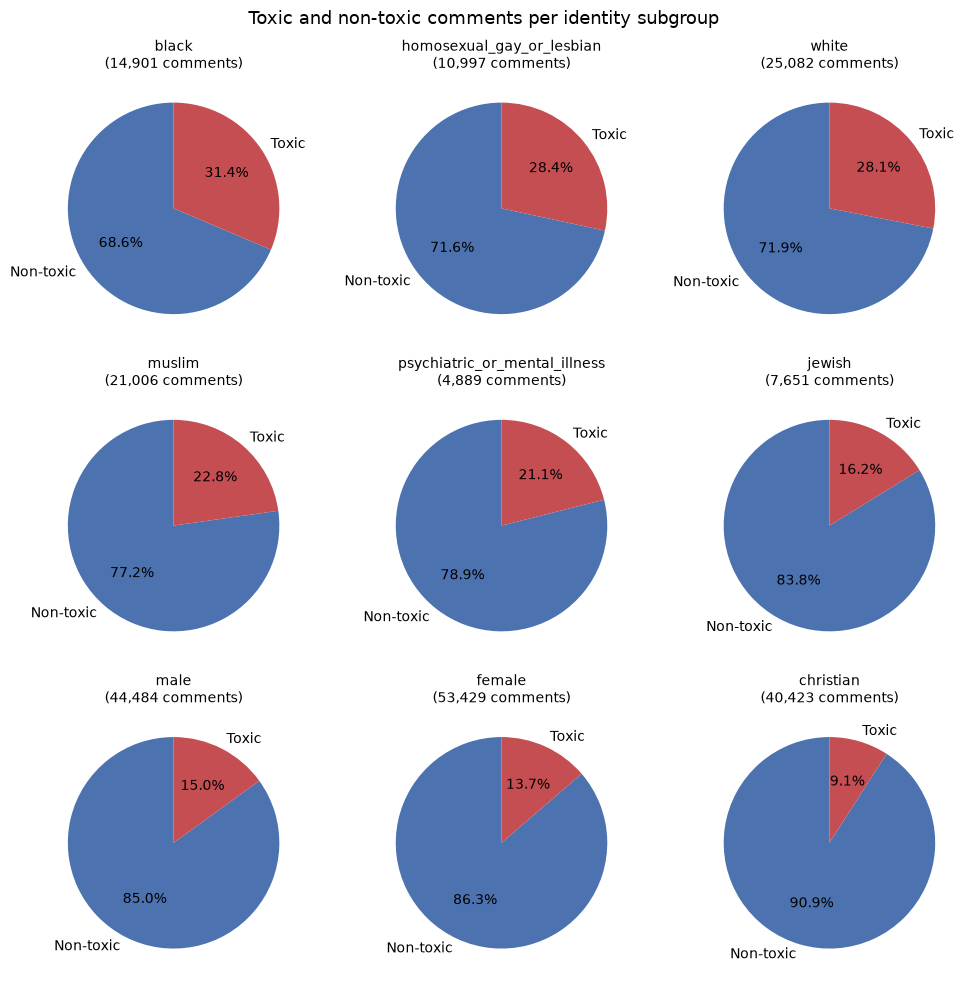

In [108]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, (name, row) in zip(axes.ravel(), toxicity_by_group.iterrows()):
    ax.pie(
        [row["non-toxic (%)"], row["toxic (%)"]],
        labels=["Non-toxic", "Toxic"],
        colors=["#4C72B0", "#C44E52"],
        autopct="%1.1f%%",
        startangle=90,
    )
    ax.set_title(f"{name}\n({int(row['comments']):,} comments)", fontsize=10)

fig.suptitle("Toxic and non-toxic comments per identity subgroup", fontsize=13)
plt.tight_layout()
plt.show()

## 5.4 Subgroup Overlap

A comment can mention several subgroups, so it counts in each of them during evaluation. Among the annotated comments, we count how many of the 9 official subgroups each comment belongs to and which pairs appear together most often.

In [109]:
in_main = df.loc[annotated, MAIN_IDENTITIES] >= 0.5
n_groups = in_main.sum(axis=1)

overlap = n_groups.clip(upper=3).value_counts().sort_index()
overlap.index = ["0", "1", "2", "3 or more"]
print("Annotated comments by number of official subgroups mentioned:")
print(overlap.to_string())

in_any = n_groups >= 1
print(f"\nComments in at least one official subgroup: {in_any.sum():,}")
print(f"Of these, in two or more: {(n_groups >= 2).sum():,} ({(n_groups >= 2).sum() / in_any.sum() * 100:.1f}%)")

Annotated comments by number of official subgroups mentioned:
0            241318
1            116442
2             37858
3 or more      9510

Comments in at least one official subgroup: 163,810
Of these, in two or more: 47,368 (28.9%)


In [110]:
# Co-occurrence: number of comments that belong to both subgroups of each pair
membership = in_main.astype(int)
co_occurrence = membership.T @ membership

pairs = [
    (a, b, co_occurrence.loc[a, b])
    for i, a in enumerate(MAIN_IDENTITIES)
    for b in MAIN_IDENTITIES[i + 1:]
]
top_pairs = pd.DataFrame(pairs, columns=["subgroup A", "subgroup B", "comments"])
top_pairs.sort_values("comments", ascending=False).head(10).reset_index(drop=True)

,subgroup A,subgroup B,comments
0,male,female,18810
1,black,white,5900
2,male,white,5570
3,female,christian,4248
4,male,christian,4009
5,christian,muslim,3548
6,female,white,2712
7,male,black,2497
8,female,muslim,2379
9,christian,jewish,2317


# 6. Key Findings for Training

1. **Strong class imbalance (8% toxic).** Models are evaluated with **F1 and ROC AUC**, not accuracy, and the split is **stratified**.
2. **Split by article.** There are 105,380 articles and the largest holds 0.08% of the data, so whole articles can be assigned to one set while keeping the 8% toxic rate in each.
3. **Cleaning before the split:**
   - remove the **3 empty texts** and the **368 comments without letters**;
   - keep **one copy per repeated text**, with `target` set to the mean of its copies.
4. **`max_length = 128`.** 15.9% of comments are truncated; this is reported as a limitation.
5. **Uncased DistilBERT.** Capitalization barely separates the classes.
6. **One third of toxic comments lie in the ambiguous zone (0.4 to 0.6).** On the test set, errors will be measured by `target` band.
7. **Subgroups:** evaluated only within the 22% of annotated comments, on the **9 official identities**. Their toxic rate ranges from 9% to 31%, so metrics must be reported per subgroup.
8. **Only the text is used as model input:** neither the number of raters nor the identity columns.
